### Notebook 04 - Unsupervised Clustering of NBA Players

This notebook implements the third part of the project: unsupervised clustering of NBA player-seasons using K-means, with evaluation against player position as the ground-truth label.

**Methodology.** We apply K-means clustering to the feature matrix of player-seasons and evaluate clustering quality with two metrics: the **Silhouette score** (an internal metric measuring how well-separated and cohesive the clusters are, based only on the feature data) and the **Rand Index** (an external metric measuring how well the cluster assignments agree with the known position labels). We will also examine clustering at multiple values of `k` to see whether the data's natural grouping structure matches the five traditional basketball positions or instead suggests a different number of player archetypes.

**Important methodological note.** Unlike Tasks 1 and 2, where position served as a *feature* used to predict performance and pay, in Task 3 position is the **ground-truth label** used to evaluate cluster quality via the Rand Index. This means position must be **removed** from the feature matrix here--otherwise the clustering would trivially recover positions because the answer is in the input.

**Inputs.** The cleaned dataset produced in Notebook 01.



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, rand_score, adjusted_rand_score

df = pd.read_csv('data/nba_clean.csv')
print(f"Loaded {len(df)} rows × {len(df.columns)} columns")

print(f"\nPosition distribution (ground truth labels):")
print(df['Pos_primary'].value_counts())

Loaded 6020 rows × 42 columns

Position distribution (ground truth labels):
Pos_primary
SG    1358
PF    1203
C     1169
PG    1164
SF    1126
Name: count, dtype: int64


## 2. Build the Feature Matrix (Without Position)

The feature matrix for clustering includes the same numerical features used in Tasks 1 and 2--per-game box-score statistics, demographics, volume, and shooting percentages--but **excludes** position. The reason is that position will serve as the ground-truth evaluation label in this task: clustering against an input that contains the answer would not be a meaningful test.

The resulting feature matrix has 30 columns. Missing (no attempts) shooting percentages are imputed with 0 as in previous notebooks.

Because K-means is distance-based and treats all features equally, we **standardize** the features to zero mean and unit variance before clustering. Without standardization, high-magnitude features (e.g., total minutes, which can range into the thousands) would dominate the distance calculation and overwhelm smaller-magnitude features (e.g., shooting percentages, which range between 0 and 1).

In [3]:
# Identifiers and labels — same as previous notebooks
identifier_cols = ['Player', 'player_id', 'Year', 'Team']
label_cols = [
    'bpm', 'bpm_rotation', 'bpm_starter', 'bpm_star', 'bpm_superstar',
    'Salary', 'salary_tier',
]

# Numerical features only — POSITION IS EXCLUDED (it's our evaluation label)
numerical_features = [c for c in df.columns
                      if c not in identifier_cols + label_cols + ['Pos_primary']]

X = df[numerical_features].fillna(0)

# Ground-truth labels for evaluation
y_position = df['Pos_primary']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"X shape: {X.shape}")
print(f"Features ({len(X.columns)}):")
print(X.columns.tolist())
print(f"\nGround-truth label classes: {sorted(y_position.unique())}")

X shape: (6020, 30)
Features (30):
['Age', 'height_in', 'weight_lb', 'experience', 'G', 'GS', 'MP', 'total_minutes', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS']

Ground-truth label classes: ['C', 'PF', 'PG', 'SF', 'SG']


## 3. K-means Clustering at k = 5

We begin with `k = 5`, the natural choice matching the five traditional basketball positions. This is the canonical comparison: do the natural statistical groupings of NBA players align with positional labels assigned by team coaches and league reporters?

K-means works by iteratively assigning each player-season to the nearest cluster centroid (in the standardized feature space) and then recomputing centroids as the mean of their assigned members. The procedure converges when assignments stop changing. We use `n_init=10` to run the algorithm from 10 random initializations and keep the best result, since K-means is sensitive to its starting centroids and can converge to local optima.

**Two evaluation metrics:**

- **Silhouette score** (range −1 to 1) is an *internal* metric that uses only the feature data. For each point, it compares the average distance to other points in its own cluster against the average distance to points in the nearest other cluster. Higher values indicate clusters that are both tight (cohesive) and well-separated. A score above 0.5 indicates strong cluster structure; 0.25-0.5 indicates moderate structure; below 0.25 indicates weak or overlapping clusters.
- **Rand Index** (range 0 to 1) is an *external* metric that compares the cluster assignments to the ground-truth position labels. It measures the fraction of all sample-pairs that are either (a) in the same cluster and the same position, or (b) in different clusters and different positions. A score of 1 means perfect agreement; 0.5 indicates roughly chance agreement.

We also report the **Adjusted Rand Index (ARI)**, which corrects the Rand Index for chance and is more interpretable: ARI = 1 is perfect agreement, ARI = 0 is the expected value under random clustering, and negative values indicate worse-than-chance agreement.

In [4]:
# K-means at k=5
kmeans_5 = KMeans(n_clusters=5, n_init=10, random_state=42)
cluster_labels_5 = kmeans_5.fit_predict(X_scaled)

# Evaluation
silhouette_5 = silhouette_score(X_scaled, cluster_labels_5)
rand_5 = rand_score(y_position, cluster_labels_5)
ari_5 = adjusted_rand_score(y_position, cluster_labels_5)

print(f"=== K-means at k=5 ===")
print(f"Silhouette score:        {silhouette_5:.4f}")
print(f"Rand Index:              {rand_5:.4f}")
print(f"Adjusted Rand Index:     {ari_5:.4f}")

# Show cluster composition by position
print(f"\nCluster composition (rows=cluster, cols=position):")
composition = pd.crosstab(cluster_labels_5, y_position)
print(composition)

=== K-means at k=5 ===
Silhouette score:        0.1682
Rand Index:              0.7045
Adjusted Rand Index:     0.1277

Cluster composition (rows=cluster, cols=position):
Pos_primary    C   PF   PG   SF   SG
row_0                               
0             12   87  330  159  222
1             81  303  412  447  520
2            379  213    4   19    3
3            661  345    7   60   14
4             36  255  411  441  599


### Results at k = 5

K-means at `k = 5` produced a silhouette score of 0.168, a Rand Index of 0.705, and an Adjusted Rand Index of 0.128 on the standardized feature matrix. The low silhouette score indicates that the data does not form five cleanly separated, cohesive groups in feature space; cluster boundaries are blurred and substantial overlap exists between groups. The Adjusted Rand Index of 0.128 — chance-corrected and therefore the more interpretable agreement metric — confirms that the clustering captures only weak positional signal: it is meaningfully better than random assignment but far from reproducing the five-position labels.

The cluster composition table makes the underlying pattern clear. Two of the five clusters (Clusters 2 and 3) are dominated almost entirely by centers and power forwards, accounting for 95% or more of their membership. The other three clusters (0, 1, and 4) contain mixed populations of point guards, shooting guards, and small forwards, with no single position dominating any of them. K-means therefore identifies a clean *big versus non-big* divide in the data but cannot distinguish between guards and wings — their statistical profiles overlap too much to support clean separation.

This pattern is itself an analytical finding. It is consistent with the well-documented modernization of the NBA toward "positionless" basketball: traditional center and power-forward roles still produce distinctive statistical signatures (high rebounds, blocks, two-point attempt rate, low three-point attempt rate), but the perimeter positions have become statistically interchangeable as point guards, shooting guards, and small forwards all increasingly handle the ball, shoot threes, and defend across positions. The fact that K-means at the "correct" number of clusters fails to recover the traditional position labels suggests that the data's natural grouping structure may not align with five positions at all--and that examining clustering at other values of k may reveal a more accurate picture of player archetype groupings.

### Investigating the Natural Number of Clusters

To test whether the data has a natural grouping structure that differs from the traditional five positions, we run K-means across a range of values of k (from 2 to 10) and examine three diagnostics at each: the silhouette score (cluster quality, independent of any external label), the Adjusted Rand Index (agreement with traditional position labels), and the within-cluster inertia (used in the classical "elbow method" for choosing k). Together these tell us whether the data favors a small number of broad archetypes (e.g., the bigs/non-bigs split observed above), the canonical five positions, or some larger number of distinct modern player roles.

In [5]:
k_values = range(2, 11)
results = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    results.append({
        'k': k,
        'silhouette': silhouette_score(X_scaled, labels),
        'rand_index': rand_score(y_position, labels),
        'adjusted_rand': adjusted_rand_score(y_position, labels),
        'inertia': km.inertia_,
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 k  silhouette  rand_index  adjusted_rand       inertia
 2    0.265744    0.479773       0.002268 129976.373181
 3    0.225809    0.612786       0.102013 112770.036453
 4    0.175755    0.663755       0.094696 100558.674319
 5    0.168245    0.704463       0.127654  91962.615454
 6    0.131998    0.724938       0.118500  87816.266460
 7    0.126382    0.730726       0.107017  84307.997086
 8    0.122766    0.744108       0.102326  81523.932364
 9    0.119998    0.757341       0.114788  79103.324208
10    0.113100    0.764318       0.111765  76986.467319


### Results

The diagnostics across k reveal three findings that converge on a single conclusion: the modern NBA is increasingly position-agnostic, and traditional position labels cannot be reliably recovered from statistical data alone.

First, the Adjusted Rand Index against position labels peaks at only 0.128 at k=5, and never exceeds this value at any other k. Even at the "correct" number of clusters, agreement between the natural statistical groupings and the five traditional positions is weak. The earlier cluster composition analysis showed why: while centers and power forwards form one statistically distinctive group (high rebounds, high two-point attempt rate, low three-point attempt rate), point guards, shooting guards, and small forwards cluster together indistinguishably. In modern basketball, *any position can fill any role*--a small forward might lead the team in assists while a power forward leads in three-point attempts and a shooting guard leads in rebounds. The statistical signatures that once defined each position (point guards lead in assists, centers grab rebounds, shooting guards take jumpers, etc.) no longer hold cleanly, and as a result, K-means cannot reconstruct positional labels from the box score alone.

Second, the inertia curve declines smoothly across all values of k with no clear elbow, indicating that NBA player statistics live on a **continuum** rather than forming discrete archetypal clusters. There is no "natural" number of player types; the data supports any number of clusters approximately equally well. This continuous structure is itself further evidence of positionlessness--if traditional positions still functioned as distinct player categories, we would expect to see sharp natural breaks in the data at or near k=5. Instead, the smooth inertia curve suggests that players span a gradient of skill combinations rather than falling into clearly separated archetypal groups.

Third, the silhouette score peaks at k=2 (0.266) rather than at k=5, and inspection of the k=2 clusters reveals that the divide is not positional. Both clusters contain similar proportions of all five positions; the actual split is by **playing time**--Cluster 1 contains rotation regulars with roughly +1 standard deviation on every volume statistic, while Cluster 0 contains limited-minutes players ~0.6 standard deviations below the mean. The strongest natural binary divide in the data, in other words, is "rotation regulars vs. bench players," not "perimeter vs. interior." Position is not even the second-most-important statistical structure in the data--role and playing time supersede it entirely.

Together these findings support an already widespread belief: traditional basketball positions are no longer well-defined statistical categories. The modern game has decoupled positional labels from statistical roles to the point that the labels themselves cannot be recovered from on-court production data. Players score, shoot threes, rebound, assist, and defend across positions, and the statistical fingerprint that once distinguished a point guard from a shooting guard or a small forward from a power forward has largely dissolved. The clustering exercise therefore serves not as a way to recover positions, but as a way to confirm a broader claim about the modern NBA: that positionlessness is now a measurable, statistical reality.

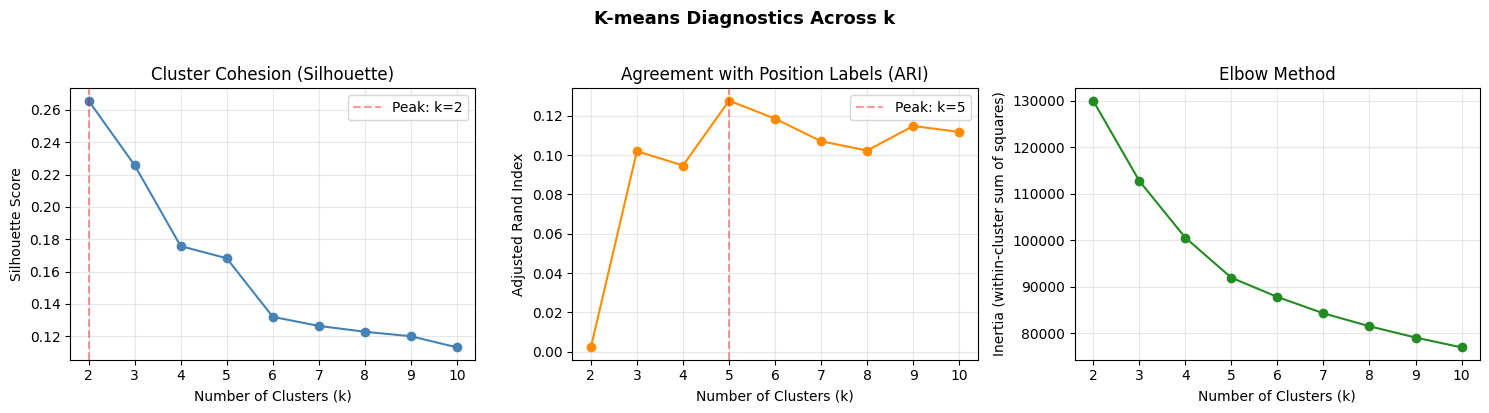

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(results_df['k'], results_df['silhouette'], marker='o', color='steelblue')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Silhouette Score')
axes[0].set_title('Cluster Cohesion (Silhouette)')
axes[0].axvline(2, linestyle='--', color='red', alpha=0.4, label='Peak: k=2')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(results_df['k'], results_df['adjusted_rand'], marker='o', color='darkorange')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Adjusted Rand Index')
axes[1].set_title('Agreement with Position Labels (ARI)')
axes[1].axvline(5, linestyle='--', color='red', alpha=0.4, label='Peak: k=5')
axes[1].grid(alpha=0.3)
axes[1].legend()

axes[2].plot(results_df['k'], results_df['inertia'], marker='o', color='forestgreen')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Inertia (within-cluster sum of squares)')
axes[2].set_title('Elbow Method')
axes[2].grid(alpha=0.3)

plt.suptitle('K-means Diagnostics Across k', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Conclusion

The three diagnostic panels above visually confirm the findings discussed: silhouette score peaks at k=2 and declines monotonically (left), Adjusted Rand Index against position labels peaks modestly at k=5 and remains low across all k (center), and inertia declines smoothly without a clear elbow (right). No value of k produces strong clustering by all three criteria simultaneously, and at no k does the clustering meaningfully recover the five traditional positions. The clustering analysis thus concludes that traditional basketball positions cannot be reconstructed from box-score statistics.